# PBL Optional Lab: 识别与修复机器学习过拟合

**Case:** Wisconsin Diagnostic Breast Cancer Dataset  
**Audience:** 大四/研一生物医学交叉专业学生  
**Purpose:** 复现课堂证据包，而不是追求最高模型分数。

本 notebook 使用 scikit-learn 内置数据，无需联网下载。它严格区分：

- **development set**：用于交叉验证、比较模型与选择复杂度；
- **locked test set**：只在模型选择结束后使用一次；
- **positive class**：malignant（恶性，记为 1）。

> 教学用途声明：本练习不构成临床诊断工具，也不支持真实临床部署。

## Learning objectives

完成本实验后，你应能：

1. 从 train-validation gap 与 learning curve 识别 overfitting；
2. 说明为什么训练集 AUC = 1.00 不能证明模型可以部署；
3. 使用 cross-validation 比较模型复杂度，而不反复查看测试集；
4. 区分 overfitting、data leakage 与 distribution shift；
5. 将“剪枝、正则化、增加数据”等措施与具体证据联系起来。

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 2026

here = Path.cwd().resolve()
if here.name == "notebook" and here.parent.name == "output":
    repo_root = here.parents[1]
else:
    repo_root = here

asset_dir = repo_root / "output" / "assets" / "pbl-overfitting"
asset_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"scikit-learn: {sklearn.__version__}")
print(f"assets: {asset_dir}")

scikit-learn: 1.8.0
assets: C:\workspace\marine-biotech-research\output\assets\pbl-overfitting


## 1. Load data and lock the test set

原始数据包含 569 个样本和 30 个由细胞核图像计算得到的连续特征。scikit-learn
原始标签中 `0 = malignant`、`1 = benign`；本实验将其改写为 `1 = malignant`，使
sensitivity 对应“找出恶性样本的比例”。

In [2]:
bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("malignant")

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

dataset_summary = pd.DataFrame({
    "partition": ["all", "development", "locked test"],
    "n": [len(y), len(y_dev), len(y_test)],
    "malignant_n": [int(y.sum()), int(y_dev.sum()), int(y_test.sum())],
    "malignant_rate": [float(y.mean()), float(y_dev.mean()), float(y_test.mean())],
})
display(dataset_summary.style.format({"malignant_rate": "{:.1%}"}))

,partition,n,malignant_n,malignant_rate
0,all,569,212,37.3%
1,development,455,170,37.4%
2,locked test,114,42,36.8%


## 2. Packet B - Model complexity

下列实验只使用 development set。对于每个决策树深度，采用
`RepeatedStratifiedKFold(5 folds x 5 repeats)`，记录训练 AUC 与验证 AUC。

观察重点：

- 深度增加时训练 AUC 如何变化？
- 验证 AUC 是否同步上升？
- 哪些深度出现明显 generalization gap？

,max_depth,train_auc_mean,train_auc_sd,cv_auc_mean,cv_auc_sd,generalization_gap
0,1,0.916,0.008,0.886,0.025,0.030
1,2,0.974,0.007,0.946,0.024,0.028
2,3,0.989,0.005,0.940,0.034,0.050
3,4,0.996,0.003,0.924,0.034,0.072
4,5,0.999,0.001,0.929,0.023,0.070
5,6,1.000,0.000,0.925,0.022,0.075
6,7,1.000,0.000,0.926,0.022,0.074
7,8,1.000,0.000,0.926,0.022,0.074
8,9,1.000,0.000,0.926,0.022,0.074
9,10,1.000,0.000,0.926,0.022,0.074


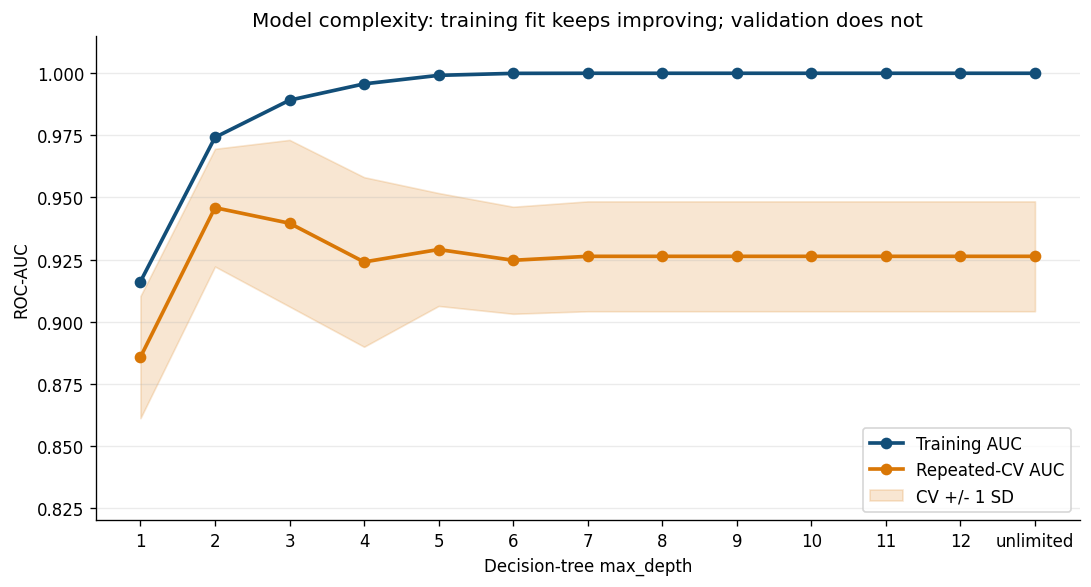

In [3]:
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE,
)

depths = list(range(1, 13)) + [None]
complexity_rows = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        scoring="roc_auc",
        cv=repeated_cv,
        return_train_score=True,
        n_jobs=1,
    )
    complexity_rows.append({
        "max_depth": "unlimited" if depth is None else str(depth),
        "train_auc_mean": scores["train_score"].mean(),
        "train_auc_sd": scores["train_score"].std(ddof=1),
        "cv_auc_mean": scores["test_score"].mean(),
        "cv_auc_sd": scores["test_score"].std(ddof=1),
        "generalization_gap": scores["train_score"].mean() - scores["test_score"].mean(),
    })

complexity_df = pd.DataFrame(complexity_rows)
display(complexity_df.style.format({
    "train_auc_mean": "{:.3f}",
    "train_auc_sd": "{:.3f}",
    "cv_auc_mean": "{:.3f}",
    "cv_auc_sd": "{:.3f}",
    "generalization_gap": "{:.3f}",
}))

x = np.arange(len(complexity_df))
fig, ax = plt.subplots(figsize=(9.2, 5.0))
ax.plot(x, complexity_df["train_auc_mean"], marker="o", lw=2.2,
        label="Training AUC", color="#124E78")
ax.plot(x, complexity_df["cv_auc_mean"], marker="o", lw=2.2,
        label="Repeated-CV AUC", color="#D97706")
ax.fill_between(
    x,
    complexity_df["cv_auc_mean"] - complexity_df["cv_auc_sd"],
    complexity_df["cv_auc_mean"] + complexity_df["cv_auc_sd"],
    alpha=0.18,
    color="#D97706",
    label="CV +/- 1 SD",
)
ax.set_xticks(x)
ax.set_xticklabels(list(range(1, 13)) + ["unlimited"])
ax.set_xlabel("Decision-tree max_depth")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.82, 1.015)
ax.set_title("Model complexity: training fit keeps improving; validation does not")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(asset_dir / "packet-b-model-complexity.png", bbox_inches="tight")
plt.show()

## 3. Packet C - Learning evidence

学习曲线改变 development set 中实际用于训练的样本数。若训练集较小，复杂模型可能
记住训练样本；若增加样本后 gap 缩小，说明“更多代表性数据”可能帮助降低 variance。

,train_n,train_auc_mean,train_auc_sd,cv_auc_mean,cv_auc_sd,generalization_gap
0,72,1.000,0.000,0.903,0.035,0.097
1,127,1.000,0.000,0.898,0.032,0.102
2,182,1.000,0.000,0.907,0.018,0.093
3,236,1.000,0.000,0.912,0.012,0.088
4,291,1.000,0.000,0.898,0.023,0.102
5,364,1.000,0.000,0.918,0.011,0.082


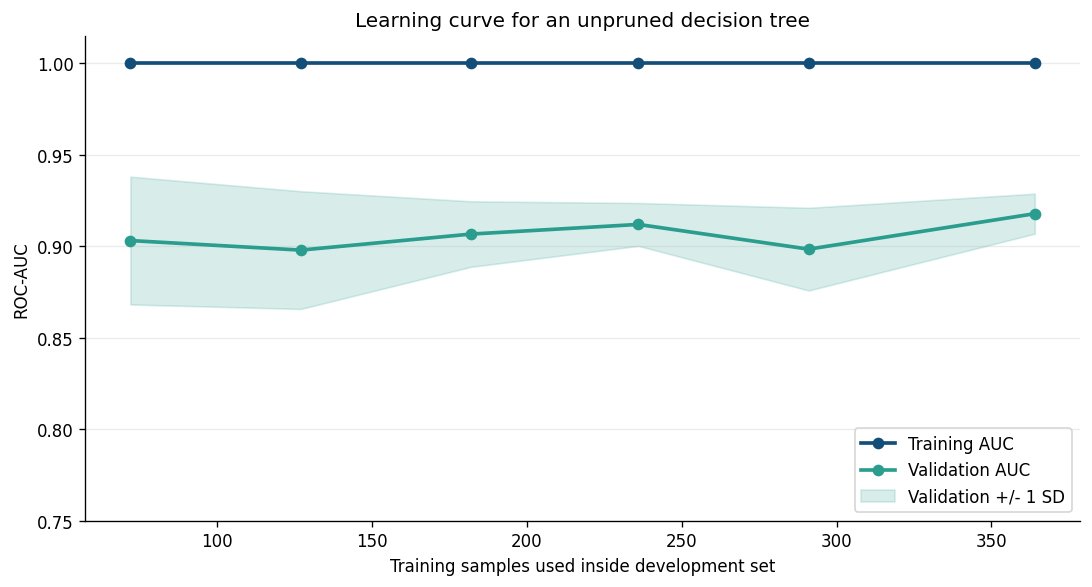

In [4]:
learning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
unpruned_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)

train_sizes_abs, train_scores, valid_scores = learning_curve(
    unpruned_tree,
    X_dev,
    y_dev,
    train_sizes=np.array([0.20, 0.35, 0.50, 0.65, 0.80, 1.00]),
    scoring="roc_auc",
    cv=learning_cv,
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

learning_df = pd.DataFrame({
    "train_n": train_sizes_abs,
    "train_auc_mean": train_scores.mean(axis=1),
    "train_auc_sd": train_scores.std(axis=1, ddof=1),
    "cv_auc_mean": valid_scores.mean(axis=1),
    "cv_auc_sd": valid_scores.std(axis=1, ddof=1),
})
learning_df["generalization_gap"] = (
    learning_df["train_auc_mean"] - learning_df["cv_auc_mean"]
)
display(learning_df.style.format({
    "train_auc_mean": "{:.3f}",
    "train_auc_sd": "{:.3f}",
    "cv_auc_mean": "{:.3f}",
    "cv_auc_sd": "{:.3f}",
    "generalization_gap": "{:.3f}",
}))

fig, ax = plt.subplots(figsize=(9.2, 5.0))
ax.plot(learning_df["train_n"], learning_df["train_auc_mean"], marker="o",
        lw=2.2, color="#124E78", label="Training AUC")
ax.plot(learning_df["train_n"], learning_df["cv_auc_mean"], marker="o",
        lw=2.2, color="#2A9D8F", label="Validation AUC")
ax.fill_between(
    learning_df["train_n"],
    learning_df["cv_auc_mean"] - learning_df["cv_auc_sd"],
    learning_df["cv_auc_mean"] + learning_df["cv_auc_sd"],
    color="#2A9D8F",
    alpha=0.18,
    label="Validation +/- 1 SD",
)
ax.set_xlabel("Training samples used inside development set")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.75, 1.015)
ax.set_title("Learning curve for an unpruned decision tree")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(asset_dir / "packet-c-learning-curve.png", bbox_inches="tight")
plt.show()

## 4. Packet D - Final audit on the locked test set

先在 development set 内比较三个**预先定义**的候选模型；模型选择结束后才打开
locked test set。Logistic regression 的标准化放在 `Pipeline` 内，因此 scaler 只会在
每个训练折上拟合。

候选模型：

- unpruned decision tree；
- shallow decision tree (`max_depth=2`)；
- L2-regularized logistic regression。

C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default va

C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\veighna_studio\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default va

,model,dev_train_auc_mean,dev_cv_auc_mean,dev_cv_auc_sd,test_roc_auc,test_accuracy,test_balanced_accuracy,test_sensitivity,test_specificity,tn,fp,fn,tp
0,Unpruned tree,1.000,0.926,0.022,0.953,0.947,0.953,0.976,0.931,67,5,1,41
1,Shallow tree (depth=2),0.974,0.946,0.024,0.966,0.930,0.939,0.976,0.903,65,7,1,41
2,L2 logistic regression,0.998,0.992,0.008,0.999,0.974,0.969,0.952,0.986,71,1,2,40


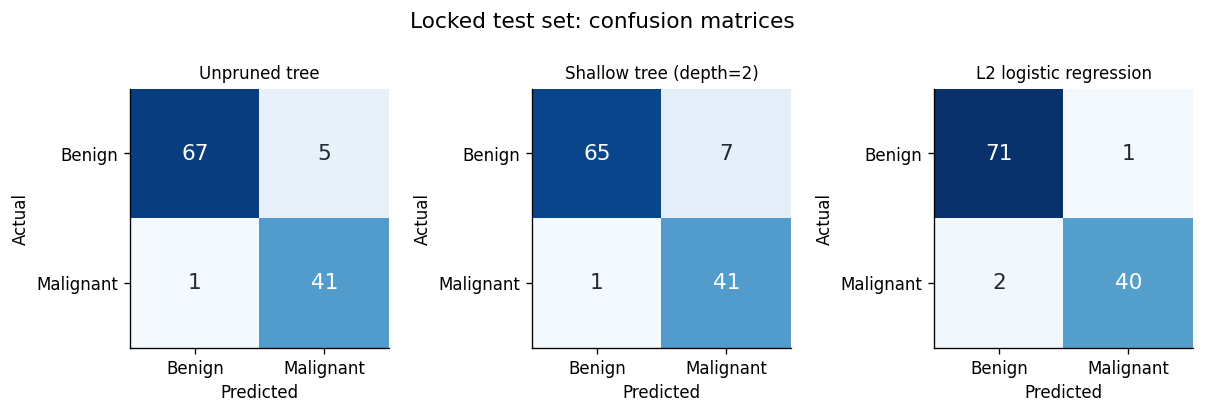

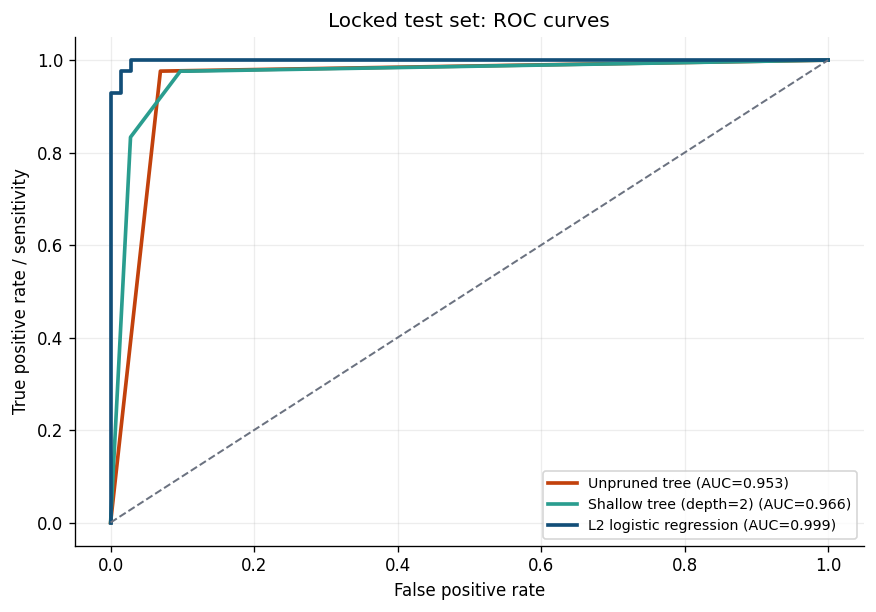

In [5]:
models = {
    "Unpruned tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Shallow tree (depth=2)": DecisionTreeClassifier(
        max_depth=2, random_state=RANDOM_STATE
    ),
    "L2 logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
    ),
}

audit_rows = []
confusion = {}
roc_data = {}

for name, model in models.items():
    cv_scores = cross_validate(
        model,
        X_dev,
        y_dev,
        scoring="roc_auc",
        cv=repeated_cv,
        return_train_score=True,
        n_jobs=1,
    )
    model.fit(X_dev, y_dev)
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    audit_rows.append({
        "model": name,
        "dev_train_auc_mean": cv_scores["train_score"].mean(),
        "dev_cv_auc_mean": cv_scores["test_score"].mean(),
        "dev_cv_auc_sd": cv_scores["test_score"].std(ddof=1),
        "test_roc_auc": roc_auc_score(y_test, prob),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "test_sensitivity": tp / (tp + fn),
        "test_specificity": tn / (tn + fp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })
    confusion[name] = np.array([[tn, fp], [fn, tp]])
    roc_data[name] = roc_curve(y_test, prob)

audit_df = pd.DataFrame(audit_rows)
display(audit_df.style.format({
    "dev_train_auc_mean": "{:.3f}",
    "dev_cv_auc_mean": "{:.3f}",
    "dev_cv_auc_sd": "{:.3f}",
    "test_roc_auc": "{:.3f}",
    "test_accuracy": "{:.3f}",
    "test_balanced_accuracy": "{:.3f}",
    "test_sensitivity": "{:.3f}",
    "test_specificity": "{:.3f}",
}))

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.25))
for ax, (name, cm) in zip(axes, confusion.items()):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(m.max() for m in confusion.values()))
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center", fontsize=13,
                color="white" if value > cm.max() * 0.55 else "#1F2937")
    ax.set_xticks([0, 1], labels=["Benign", "Malignant"])
    ax.set_yticks([0, 1], labels=["Benign", "Malignant"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=10)
fig.suptitle("Locked test set: confusion matrices", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(asset_dir / "packet-d-confusion-matrices.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 5.2))
colors = ["#C2410C", "#2A9D8F", "#124E78"]
for (name, (fpr, tpr, _)), color in zip(roc_data.items(), colors):
    auc = float(audit_df.loc[audit_df["model"] == name, "test_roc_auc"].iloc[0])
    ax.plot(fpr, tpr, lw=2.2, color=color, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#6B7280", lw=1.2)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate / sensitivity")
ax.set_title("Locked test set: ROC curves")
ax.grid(alpha=0.22)
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig(asset_dir / "packet-d-roc-curves.png", bbox_inches="tight")
plt.show()

## 5. Reproducibility checks and exports

这些断言只检查教学证据是否稳定复现，不是在为模型“颁发部署许可证”。

In [6]:
unlimited = complexity_df.loc[complexity_df["max_depth"] == "unlimited"].iloc[0]
assert unlimited["train_auc_mean"] >= 0.999
assert unlimited["generalization_gap"] >= 0.05
assert len(y_test) == 114
assert int(y_test.sum()) == 42
assert set(audit_df["model"]) == set(models)

complexity_df.to_csv(asset_dir / "packet-b-model-complexity.csv", index=False)
learning_df.to_csv(asset_dir / "packet-c-learning-curve.csv", index=False)
audit_df.to_csv(asset_dir / "packet-d-final-audit.csv", index=False)
dataset_summary.to_csv(asset_dir / "dataset-summary.csv", index=False)

export = {
    "random_state": RANDOM_STATE,
    "dataset": {
        "name": "Wisconsin Diagnostic Breast Cancer",
        "n_total": int(len(y)),
        "n_features": int(X.shape[1]),
        "n_development": int(len(y_dev)),
        "n_test": int(len(y_test)),
        "test_malignant": int(y_test.sum()),
        "positive_class": "malignant",
    },
    "complexity": complexity_df.to_dict(orient="records"),
    "learning_curve": learning_df.to_dict(orient="records"),
    "final_audit": audit_df.to_dict(orient="records"),
    "sklearn_version": sklearn.__version__,
}
with (asset_dir / "metrics.json").open("w", encoding="utf-8") as handle:
    json.dump(export, handle, ensure_ascii=False, indent=2)

print("Reproducibility checks passed.")
print(f"Metrics written to: {asset_dir / 'metrics.json'}")

Reproducibility checks passed.
Metrics written to: C:\workspace\marine-biotech-research\output\assets\pbl-overfitting\metrics.json


## 6. Reflection prompts

1. 哪一项证据最能反驳“训练 AUC = 1.00，所以可以部署”？为什么？
2. 如果先对全部 569 个样本做标准化，再划分数据，会引入什么风险？
3. 如果另一个医院的扫描设备和患者构成不同，即使本测试集表现很好，还缺少什么证据？
4. “增加模型复杂度”“增加代表性样本”“重复查看测试集”三种做法中，哪些可能缩小真正的泛化误差，哪些只会让报告数字更漂亮？

**建议结论形式：** 不要只写“模型过拟合”。请写明证据、可能原因、修复方案、验证方式以及当前不能下的结论。